<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 1 of 3</b>: Group Member Contribution, Abstract, I. Identifying Business Needs, II. Data Exploration and Preprocessing. Notebook 2 holds Section III, Notebook 3 holds Sections IV and V. The three notebooks share the functions in <b>preprocessing.py</b>, each function is introduced and checked in Section II.</p>

</div>

<a id="contribution"></a>

<h1>Group Member Contribution</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Tiago (25%)</b>: </li>
  <li><b>Kilian (25%)</b>: </li>
  <li><b>Pia (25%)</b>: </li>
  <li><b>Chantal (25%)</b>: </li>
</ul>

</div>

<a id="abstract"></a>

<h1>Abstract</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Everything & Then Some, Ltd. is a wholesale company whose customers buy in very different rhythms. The company wants to know whether a customer will buy again within 90 days of a purchase. We work with 6,534 historical purchases of 610 customers (2015 to 2025) and predict 986 later purchases for a Kaggle competition scored with the F1.</p>
<p>Our goals were a cleaning justified by the data, one consistent model assessment and a model that still works on later purchases. Because the test data lies in the future, every decision is taken on four time folds with a 90-day gap, and the newest period is a holdout that no decision has seen. We repaired impossible values, transformed the skewed amounts with log1p and built ten new variables, among them a customer history that only uses earlier purchases. A filter, a wrapper (RFE) and an embedded method (L1) voted on 40 candidate variables. The 21 variables with at least two votes perform as well as all 40 and form the final set. On this set we tuned eight algorithms with grid and random search: logistic regression, Naive Bayes, kNN, decision tree, neural network, random forest, gradient boosting and voting.</p>
<p>The default tree models overfit strongly, and after tuning the best five models are within 0.002 F1. We chose the simplest one, a logistic regression with a strong L2 penalty. It reaches an F1 of 0.755 on the time folds and 0.784 on the holdout (AUC 0.815), against 0.753 for always predicting a repeat. The open-ended section shows that the purchase rhythm of the customer drives the prediction, that the errors sit with occasional buyers, and that the probabilities can rank customers for a contact list. We conclude that a simple, well-regularised model on few variables is enough.</p>

</div>

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association
from sklearn.metrics import roc_auc_score

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import preprocessing as prep
from preprocessing import TARGET, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# test.csv is not read in this notebook: it is only used in the deployment (Notebook 3)
raw_train, clientes = prep.load_train("../data/raw")
print("train:", raw_train.shape, " clientes:", clientes.shape)

train: (6534, 39)  clientes: (1143, 13)


<a id="business"></a>

<h1>I. Identifying Business Needs</h1>

<h2>Overview and main goals of the project</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Business question</b>: at the moment of a purchase, Everything & Then Some, Ltd. wants to know whether the customer will buy again within 90 days, so that commercial actions can be targeted</li>
  <li><b>Machine learning task</b>: binary classification. One row is one purchase, the target <b>repeat_purchase_90d</b> is 1 if the customer buys again within 90 days</li>
  <li><b>Goals</b>: clean the data with evidence, select features and compare classifiers under one assessment strategy, predict test.csv for Kaggle (metric: F1), and give the company insights beyond the score</li>
</ul>

</div>

<h2>Description of the overall process and identification of model assessment approach</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Notebook 1</b>: exploration, cleaning rules and new features (Section II)</li>
  <li><b>Notebook 2</b>: feature selection, eight algorithms and their optimization, final check on a holdout (Section III)</li>
  <li><b>Notebook 3</b>: what drives the prediction and where it fails (Section IV), raw test.csv to the Kaggle file (Section V)</li>
  <li><b>test.csv only tests the final model</b>: it is read for the first time in the deployment. No exploration, cleaning rule, decision or fitted step in Notebooks 1 and 2 uses it</li>
  <li>The model will be used on purchases made <b>after</b> the training period, so the assessment has to answer: how good is it on later purchases? The figure shows the split of train.csv used in all three notebooks</li>
</ul>

</div>

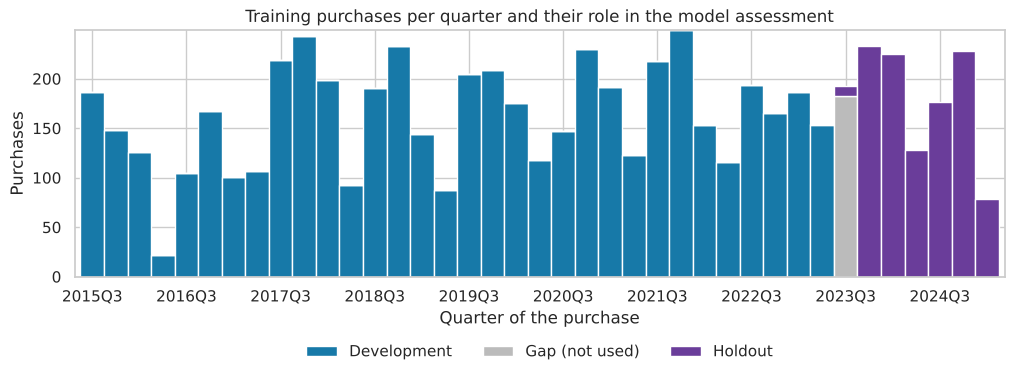

In [3]:
train = prep.prepare_purchases(raw_train, clientes)
development, holdout, inner_folds = prep.split_development_holdout(train)

# role of every training purchase in the model assessment
in_development = train["ID"].isin(development["ID"])
in_holdout = train["ID"].isin(holdout["ID"])
role = np.select([in_development, in_holdout], ["Development", "Holdout"], "Gap (not used)")
quarters = pd.DataFrame({"quarter": pd.PeriodIndex(train["purchase_date"], freq="Q"), "role": role})
per_quarter = quarters.groupby(["quarter", "role"]).size().unstack(fill_value=0)
per_quarter = per_quarter[["Development", "Gap (not used)", "Holdout"]]
per_quarter.index = per_quarter.index.astype(str)

ax = per_quarter.plot(kind="bar", stacked=True, width=1.0, figsize=(12, 3.2),
                      color=[PLOT_BLUE, "#BBBBBB", PLOT_PURPLE])
ax.set_xticks(range(0, len(per_quarter), 4))
ax.set_xticklabels(per_quarter.index[::4], rotation=0)
ax.set(title="Training purchases per quarter and their role in the model assessment",
       xlabel="Quarter of the purchase", ylabel="Purchases")
ax.legend(title="", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.show()

In [4]:
dev_dates = pd.to_datetime(development["purchase_date"])
holdout_dates = pd.to_datetime(holdout["purchase_date"])

# no fold may look into the future: every 90-day target window ends before the validation starts
for train_idx, val_idx in inner_folds:
    assert dev_dates.iloc[train_idx].max() + pd.Timedelta(days=90) < dev_dates.iloc[val_idx].min()
assert dev_dates.max() + pd.Timedelta(days=90) < holdout_dates.min()
assert not development["ID"].isin(holdout["ID"]).any()

fold_rows = []
for train_idx, val_idx in inner_folds:
    fold_rows.append({
        "Training rows": len(train_idx),
        "Training until": f"{dev_dates.iloc[train_idx].max():%b %Y}",
        "Validation rows": len(val_idx),
        "Validation from": f"{dev_dates.iloc[val_idx].min():%b %Y}",
        "Validation until": f"{dev_dates.iloc[val_idx].max():%b %Y}",
        "Repeat rate in validation": round(development[TARGET].iloc[val_idx].mean(), 3),
    })
display(pd.DataFrame(fold_rows, index=pd.RangeIndex(1, 5, name="Inner fold")))
n_gap = len(train) - len(development) - len(holdout)
print(f"Development: {len(development)} rows, gap: {n_gap} rows, holdout: {len(holdout)} rows")
print(f"Holdout period: {holdout_dates.min():%Y-%m-%d} to {holdout_dates.max():%Y-%m-%d}, "
      f"repeat rate {holdout[TARGET].mean():.3f}")

,Training rows,Training until,Validation rows,Validation from,Validation until,Repeat rate in validation
Inner fold,,,,,,
1,932,May 2017,1041,Aug 2017,Dec 2018,0.591
2,1885,Sep 2018,1041,Dec 2018,Jul 2020,0.530
3,2992,Apr 2020,1041,Jul 2020,Nov 2021,0.581
4,3903,Aug 2021,1041,Nov 2021,Jun 2023,0.510


Development: 5207 rows, gap: 184 rows, holdout: 1078 rows
Holdout period: 2023-09-25 to 2025-02-15, repeat rate 0.604


<h3>Model assessment approach</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Holdout by time</b>: the newest 1,078 purchases (25 Sep 2023 to 15 Feb 2025) are set aside and used once, for the final model</li>
  <li><b>Cross-validation by time</b>: every decision is taken on the same 4 time folds of the development part (<b>TimeSeriesSplit</b>: train on the past, validate on the next period). Each validation period has 1,041 rows</li>
  <li><b>90-day gap</b>: the target looks 90 days ahead, so a training row only stays if its 90 days end before the validation period starts. The <b>assert</b> lines in the cell above check this for every fold and for the holdout</li>
  <li><b>Why not a random split or LOO</b>: rows of one customer are not independent (Insight 1) and the model is used on later purchases, so a random split would show the model the future of its own customers. Notebook 2 measures time folds against folds by customer</li>
  <li><b>Metric</b>: F1 of the repeat class, the Kaggle metric, for every decision. The AUC is reported next to it</li>
  <li><b>No leakage</b>: median, scaling, one-hot levels, feature selection and model are steps of one pipeline, fitted on the training rows of each fold only</li>
</ul>

</div>

<a id="exploration"></a>

<h1>II. Data Exploration and Preprocessing</h1>

<h2>Description of data received -> key insights</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>train.csv has 39 columns: <b>ID</b>, <b>customer_id</b>, the target and 36 further columns (current invoice, purchase history, rolling windows, categories, date, <b>random_noise</b>). clientes.csv has one row per customer. We only show what leads to a decision.</p>

</div>

<h3>1. Observations</h3>

In [5]:
# size of the data, rows per customer and time period
rows_per_customer = raw_train.groupby("customer_id").size()
top_10_share = rows_per_customer.nlargest(10).sum() / len(raw_train)
train_dates = pd.to_datetime(raw_train["purchase_date"])
has_history = raw_train["prior_purchase_count"] > 0

print(f"Rows in train: {len(raw_train)}")
print(f"Customers in train: {raw_train['customer_id'].nunique()}, "
      f"median rows per customer: {rows_per_customer.median():.0f}, "
      f"most rows of one customer: {rows_per_customer.max()}")
print(f"Share of rows from the 10 biggest customers: {top_10_share:.1%}")
print(f"Train period: {train_dates.min():%Y-%m-%d} to {train_dates.max():%Y-%m-%d}")
share_with_history = has_history.sum() / raw_train["purchase_date"].notna().sum()
print(f"Purchases of customers who bought before: {share_with_history:.1%}")
print(f"Repeat rate in train: {raw_train[TARGET].mean():.3f}")

Rows in train: 6534
Customers in train: 610, median rows per customer: 4, most rows of one customer: 277
Share of rows from the 10 biggest customers: 17.5%
Train period: 2015-07-11 to 2025-02-15
Purchases of customers who bought before: 90.7%
Repeat rate in train: 0.559


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>One row is one purchase, but there are only <b>610 customers</b> (median 4 rows, one has 277) --> rows of one customer are <b>not independent</b></li>
  <li>train.csv covers almost 10 years, and <b>90.7%</b> of the purchases come from customers who bought before --> the model mostly predicts known customers at a later time, so we validate <b>by time</b> (Section I)</li>
  <li><b>55.9%</b> of the purchases are followed by a repeat --> accuracy says little, and the baseline for the F1 is high</li>
</ul>

</div>

<h3>2. Missing values</h3>

In [6]:
feature_columns = [col for col in raw_train.columns if col not in ["ID", "customer_id", TARGET]]
is_empty = raw_train[feature_columns].isna().all(axis=1)
filled_train = raw_train[~is_empty]

# share of missing values by the number of earlier purchases
prior_group = filled_train["prior_purchase_count"].clip(upper=3).astype(int).astype(str)
prior_group = prior_group.replace("3", "3+")
gap_columns = ["days_since_previous_purchase", "prior_std_purchase_value", "prior_mean_gap_days",
               "prior_std_gap_days", "spend_365d", "payment_type"]
missing_share = filled_train[gap_columns].isna().groupby(prior_group).mean().T.round(3)
display(missing_share.rename_axis("Share missing").rename_axis("Earlier purchases", axis=1))

is_first = filled_train["prior_purchase_count"] == 0
print(f"Rows without any feature value: {is_empty.sum()}, "
      f"their repeat rate: {raw_train.loc[is_empty, TARGET].mean():.3f}")
print(f"Repeat rate of first purchases: {filled_train.loc[is_first, TARGET].mean():.3f}, "
      f"of all other purchases: {filled_train.loc[~is_first, TARGET].mean():.3f}")

Earlier purchases,0,1,2,3+
Share missing,,,,
days_since_previous_purchase,1.000,0.043,0.055,0.030
prior_std_purchase_value,1.000,1.000,0.000,0.000
prior_mean_gap_days,1.000,1.000,0.058,0.034
prior_std_gap_days,1.000,1.000,1.000,0.000
spend_365d,0.030,0.043,0.041,0.028
payment_type,0.032,0.013,0.030,0.031


Rows without any feature value: 65, their repeat rate: 0.508
Repeat rate of first purchases: 0.333, of all other purchases: 0.583


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li><b>65 rows</b> have no feature value and repeat like the average (0.508) --> dropped from train. Rows of a new file are never dropped (Notebook 3)</li>
  <li>The gaps in the history columns are <b>structural</b>: with 0 earlier purchases no history exists, with 1 no standard deviation and no gap, with 2 no standard deviation of the gaps</li>
  <li>First purchases repeat only <b>33.3%</b> against 58.3% --> the gap is information: these values get a <b>0 and two flags</b>. Notebook 2 tests this against the median</li>
  <li>The other gaps (about 3% per column) do not depend on the history --> <b>training median</b> for numbers, level <b>"missing"</b> for categories, inside the pipeline</li>
</ul>

</div>

<h3>3. Implausible values</h3>

In [7]:
# number of rows with each kind of impossible value
def count_problems(purchases):
    prior_spend = purchases["prior_total_spend"]
    expected_mean = prior_spend / purchases["prior_purchase_count"]
    mean_error = (purchases["prior_mean_purchase_value"] - expected_mean).abs()
    return pd.Series({
        "Placeholder 1e9": ((purchases["prior_mean_purchase_value"] >= 1e8)
                            | (purchases["spend_365d"] >= 1e8)).sum(),
        "Negative amount": ((purchases["prior_mean_purchase_value"] < 0)
                            | (purchases["spend_365d"] < 0)).sum(),
        "Day code -4": ((purchases["days_since_previous_purchase"] < 0)
                        | (purchases["prior_mean_gap_days"] < 0)).sum(),
        "Mean differs from total / count": (mean_error > 0.02).sum(),
        "Maximum above total spend": (purchases["prior_max_purchase_value"] > prior_spend + 0.01).sum(),
        "spend_365d above total spend": ((purchases["spend_365d"] > prior_spend + 0.01)
                                         & (purchases["spend_365d"] < 1e8)).sum(),
    })


pd.DataFrame({
    "Train before the repair": count_problems(filled_train),
    "Train after the repair": count_problems(prep.repair_values(filled_train)),
}).rename_axis("Problem")

,Train before the repair,Train after the repair
Problem,,
Placeholder 1e9,31,0
Negative amount,31,0
Day code -4,32,0
Mean differs from total / count,78,0
Maximum above total spend,45,0
spend_365d above total spend,39,0


In [8]:
# can the wrong values be recomputed from other columns?
negative_mean = filled_train["prior_mean_purchase_value"] < 0
correct_mean = filled_train["prior_total_spend"] / filled_train["prior_purchase_count"]
sign_flipped = np.isclose(-filled_train.loc[negative_mean, "prior_mean_purchase_value"],
                          correct_mean[negative_mean])
net_plus_tax = filled_train["Total Liquido"] + filled_train["Total Imp_"]
gross_minus_discounts = (filled_train["Total Bruto"] - filled_train["Total Desc_ Linha"]
                         - filled_train["Total Desc_ Global"])
payable_rule = (filled_train["Total a Pagar"] - net_plus_tax).abs() < 0.02
net_rule = (filled_train["Total Liquido"] - gross_minus_discounts).abs() < 0.02

print(f"Negative means that are the correct mean with a minus: {sign_flipped.mean():.0%}")
print(f"Rows with Total a Pagar = Total Liquido + Total Imp_: {payable_rule.mean():.0%}")
print(f"Rows with Total Liquido = Total Bruto - discounts: {net_rule.mean():.0%}")

Negative means that are the correct mean with a minus: 100%
Rows with Total a Pagar = Total Liquido + Total Imp_: 100%
Rows with Total Liquido = Total Bruto - discounts: 100%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b> (function <b>repair_values</b>)</p>
<ul>
  <li><b>prior_mean_purchase_value</b> (placeholder 1e9, negative or wrong in 78 rows) --> recomputed as total spend / count. Every negative mean is the correct mean with a minus, so the mean follows from two other columns</li>
  <li><b>Day code -4</b> (32 values) --> missing: -4 days is a code and not a number of days</li>
  <li><b>prior_max_purchase_value</b> above the total spend</b> (45 rows) --> missing: one purchase can not be bigger than the total, and the maximum can not be recomputed</li>
  <li><b>spend_365d</b> --> 1e9 to missing, sign removed, values above the total to missing</li>
  <li><b>Total a Pagar</b>, <b>Total Bruto</b> --> not used: both invoice rules hold in 100% of the rows, so the two columns are sums of other columns</li>
  <li>The repair is a function with fixed rules, so the same rules run on every new file (Notebook 3)</li>
</ul>

</div>

<h3>4. Skewed amounts and outliers</h3>

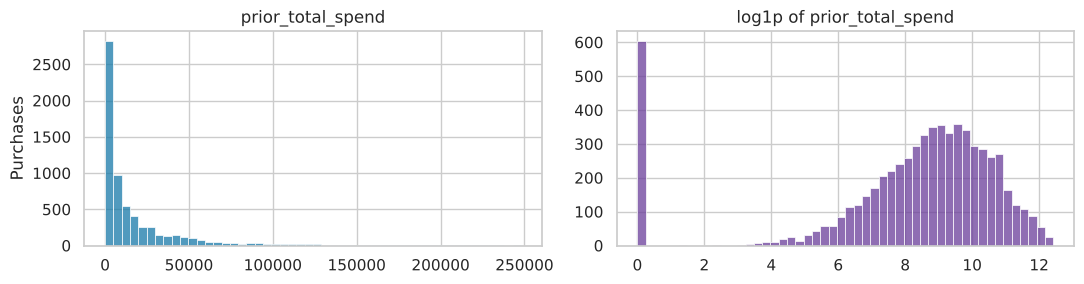

Median absolute skew: 3.75, after log1p: 0.74
Rows above the IQR bound: 642, their repeat rate: 0.841, repeat rate of the other rows: 0.529


In [9]:
repaired_train = prep.repair_values(filled_train)
skew_before = repaired_train[prep.SUPPLIED_NUMERIC].skew()
skew_after = np.log1p(repaired_train[prep.SUPPLIED_NUMERIC].clip(lower=0)).skew()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.histplot(repaired_train["prior_total_spend"], bins=50, color=PLOT_BLUE, ax=axes[0])
axes[0].set(title="prior_total_spend", xlabel="", ylabel="Purchases")
sns.histplot(np.log1p(repaired_train["prior_total_spend"]), bins=50, color=PLOT_PURPLE, ax=axes[1])
axes[1].set(title="log1p of prior_total_spend", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# IQR rule on the total spend: are the outliers errors or big customers?
q1, q3 = repaired_train["prior_total_spend"].quantile([0.25, 0.75])
is_outlier = repaired_train["prior_total_spend"] > q3 + 1.5 * (q3 - q1)
print(f"Median absolute skew: {skew_before.abs().median():.2f}, "
      f"after log1p: {skew_after.abs().median():.2f}")
print(f"Rows above the IQR bound: {is_outlier.sum()}, their repeat rate: "
      f"{filled_train.loc[is_outlier, TARGET].mean():.3f}, repeat rate of the other rows: "
      f"{filled_train.loc[~is_outlier, TARGET].mean():.3f}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>Amounts, counts and day columns are strongly right skewed (median absolute skew <b>3.75</b>), <b>log1p</b> brings it to <b>0.74</b> --> <b>log1p</b>, then scaling, inside the pipeline. Notebook 2 measures what <b>log1p</b> adds</li>
  <li>The 642 rows above the IQR bound of <b>prior_total_spend</b> are <b>big customers</b>, not errors: they repeat <b>84.1%</b> against 52.9% --> kept</li>
</ul>

</div>

<h3>5. Relationship with the target</h3>

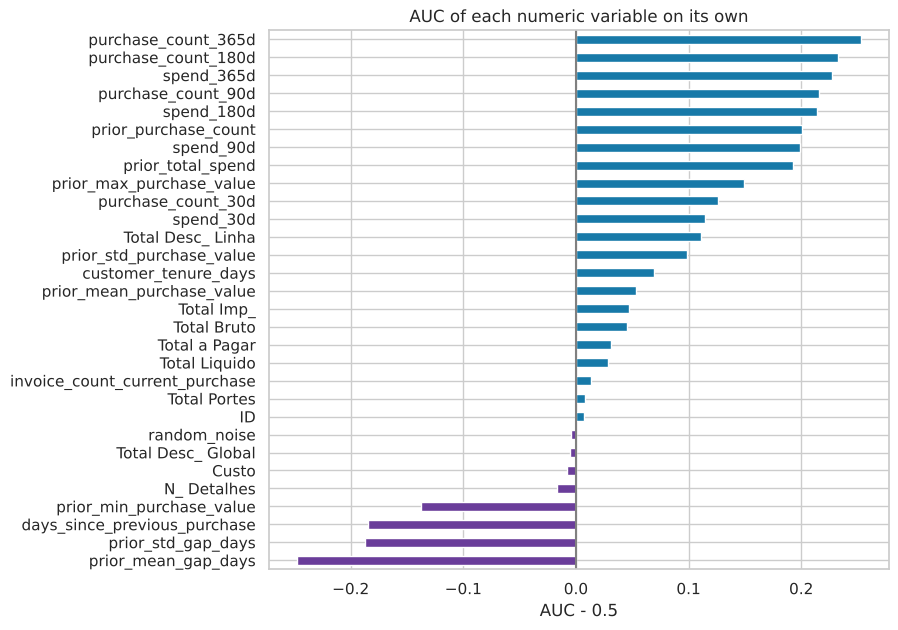

{'purchase_count_365d': 0.753, 'prior_mean_gap_days': 0.252, 'Total Liquido': 0.529, 'random_noise': 0.495, 'ID': 0.507}


In [10]:
# AUC of every numeric column on its own: 0.5 means no signal,
# below 0.5 means "higher value, fewer repeats"
single_columns = prep.SUPPLIED_NUMERIC + ["Total a Pagar", "Total Bruto", "random_noise", "ID"]
single_auc = {}
for col in single_columns:
    has_value = repaired_train[col].notna()
    single_auc[col] = roc_auc_score(filled_train.loc[has_value, TARGET],
                                    repaired_train.loc[has_value, col])
single_auc = pd.Series(single_auc).sort_values()

colors = np.where(single_auc >= 0.5, PLOT_BLUE, PLOT_PURPLE)
ax = (single_auc - 0.5).plot(kind="barh", figsize=(8, 7), color=colors)
ax.axvline(0, color="grey")
ax.set(title="AUC of each numeric variable on its own", xlabel="AUC - 0.5", ylabel="")
plt.show()
examples = ["purchase_count_365d", "prior_mean_gap_days", "Total Liquido", "random_noise", "ID"]
print(single_auc[examples].round(3).to_dict())

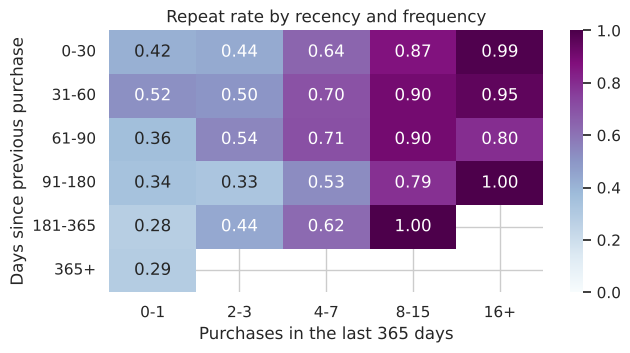

In [11]:
# repeat rate by recency (rows) and frequency (columns)
recency = pd.cut(repaired_train["days_since_previous_purchase"], [0, 30, 60, 90, 180, 365, 5000],
                 labels=["0-30", "31-60", "61-90", "91-180", "181-365", "365+"], include_lowest=True)
frequency = pd.cut(repaired_train["purchase_count_365d"], [-1, 1, 3, 7, 15, 500],
                   labels=["0-1", "2-3", "4-7", "8-15", "16+"])
repeat_rate = pd.crosstab(recency, frequency, values=filled_train[TARGET], aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 3.4))
sns.heatmap(repeat_rate, annot=True, fmt=".2f", cmap="BuPu", vmin=0, vmax=1, ax=ax)
ax.set(title="Repeat rate by recency and frequency", xlabel="Purchases in the last 365 days",
       ylabel="Days since previous purchase")
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The strongest variables describe <b>how often and how regularly</b> a customer buys: <b>purchase_count_365d</b> (AUC 0.75), <b>prior_mean_gap_days</b> (0.25: short gaps, more repeats). The current invoice says little (<b>Total Liquido</b> 0.53)</li>
  <li><b>random_noise</b> (0.495) and <b>ID</b> (0.507) have no signal --> <b>random_noise</b> stays as a <b>benchmark</b> in the feature selection: a method that keeps it is not selective enough</li>
  <li>The heatmap shows that frequency matters at every recency: in each row the repeat rate rises from left to right --> the customer's <b>own rhythm</b> is what the new features describe (Step 3)</li>
</ul>

</div>

<h3>6. Categorical variables and identifiers</h3>

In [12]:
# levels, biggest level, link with the target and customers per level of every category
category_columns = ["transport_method", "payment_type", "salesperson", "commercial_zone", "warehouse",
                    "document_series"]
category_check = {}
for col in category_columns:
    level_counts = filled_train[col].value_counts()
    crosstab = pd.crosstab(filled_train[col].fillna("missing"), filled_train[TARGET])
    customers_per_level = filled_train.groupby(col)["customer_id"].nunique()
    category_check[col] = {
        "Levels": len(level_counts),
        "Share of the biggest level": round(level_counts.iloc[0] / level_counts.sum(), 3),
        "Cramér's V with the target": round(association(crosstab, method="cramer"), 3),
        "Levels used by one customer only": (customers_per_level == 1).sum(),
    }
display(pd.DataFrame(category_check).T.rename_axis("Variable"))

series_periods = filled_train.groupby("document_series")["purchase_date"].agg(["min", "max"])
for series, period in series_periods.iterrows():
    print(f"{series}: purchases from {period['min']} to {period['max']}")

,Levels,Share of the biggest level,Cramér's V with the target,Levels used by one customer only
Variable,,,,
transport_method,80.0,0.178,0.285,40.0
payment_type,9.0,0.728,0.234,0.0
salesperson,9.0,0.646,0.201,0.0
commercial_zone,5.0,0.968,0.064,2.0
warehouse,2.0,0.997,0.040,0.0
document_series,3.0,0.423,0.003,0.0


Ctrl Z Series 1: purchases from 2017-04-05 to 2021-05-16
Ctrl Z Series 2: purchases from 2021-05-22 to 2025-02-15
Ctrl Z Series 3: purchases from 2015-07-11 to 2021-05-17


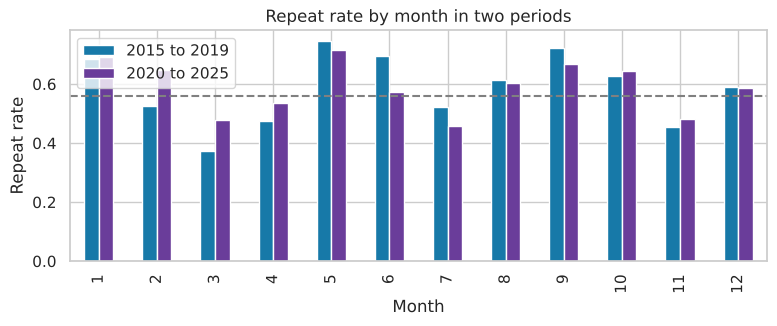

Correlation of the monthly pattern between the two periods: 0.81


In [13]:
# repeat rate per month in two periods
month = pd.to_datetime(filled_train["purchase_date"]).dt.month
is_early = pd.to_datetime(filled_train["purchase_date"]).dt.year <= 2019
rate_by_month = pd.DataFrame({
    "2015 to 2019": filled_train[is_early].groupby(month[is_early])[TARGET].mean(),
    "2020 to 2025": filled_train[~is_early].groupby(month[~is_early])[TARGET].mean(),
})
ax = rate_by_month.plot(kind="bar", figsize=(9, 3), color=[PLOT_BLUE, PLOT_PURPLE])
ax.axhline(filled_train[TARGET].mean(), color="grey", linestyle="--")
ax.set(title="Repeat rate by month in two periods", xlabel="Month", ylabel="Repeat rate")
plt.show()
print(f"Correlation of the monthly pattern between the two periods: "
      f"{rate_by_month['2015 to 2019'].corr(rate_by_month['2020 to 2025']):.2f}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b>: identifier-like variables are checked before any model sees them</p>
<ul>
  <li><b>ID</b> --> not used: one value per row, AUC 0.51</li>
  <li><b>customer_id</b> --> only for the join and the customer history: as a feature the model would learn single customers by heart</li>
  <li><b>transport_method</b> --> not used: 80 levels, <b>40 of them used by one customer only</b>, a hidden customer identifier</li>
  <li><b>commercial_zone</b> --> not used: 96.8% of the rows have the same level</li>
  <li><b>warehouse</b> --> not used: 99.7% one level</li>
  <li><b>document_series</b> --> not used: no link with the target (V 0.003), and since May 2021 only Series 2 is used, so it is a time stamp that is constant for later purchases</li>
  <li><b>payment_type</b>, <b>salesperson</b> --> candidates, one-hot: 9 levels each, used by many customers, clear link with the target (V 0.23 and 0.20)</li>
  <li><b>purchase_date</b> --> only the month, as a category: the monthly pattern is similar in 2015 to 2019 and 2020 to 2025 (correlation 0.81), the year can not be learned for later data</li>
</ul>

</div>

<h3>7. Redundant variables</h3>

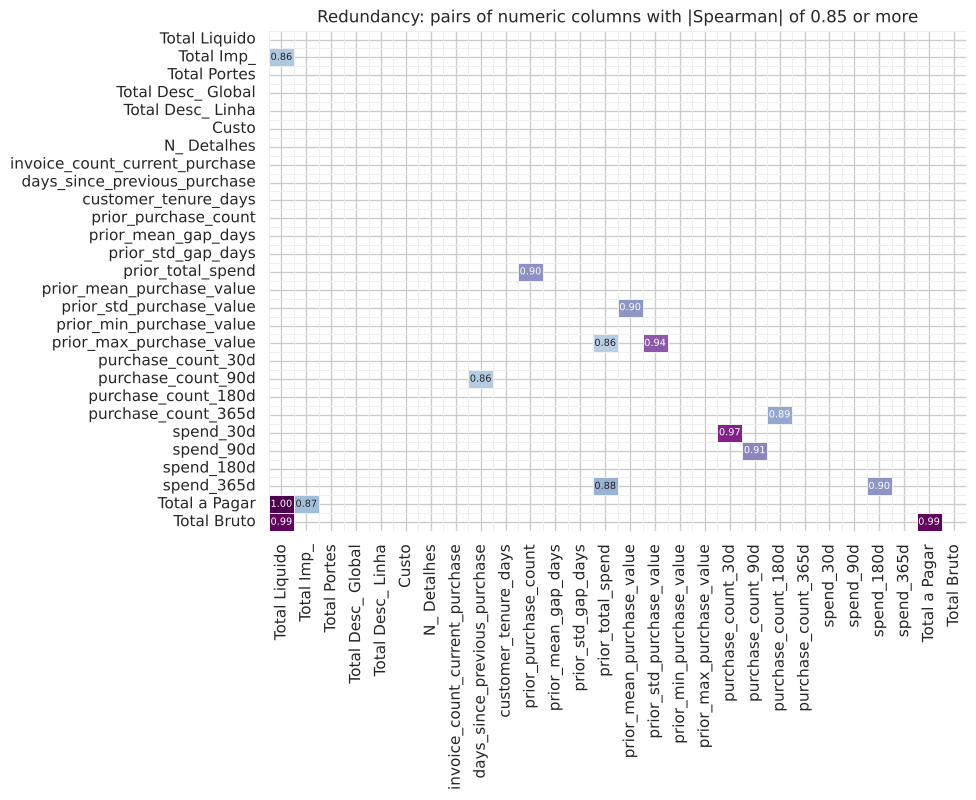

Pairs with a Spearman correlation of 0.85 or more: 15


In [14]:
# pairs of supplied numeric columns with a Spearman correlation of 0.85 or more
supplied_columns = prep.SUPPLIED_NUMERIC + ["Total a Pagar", "Total Bruto"]
spearman = repaired_train[supplied_columns].corr(method="spearman").abs()
lower_triangle = np.tril(np.ones(spearman.shape, dtype=bool), k=-1)
strong_pairs = spearman.where(lower_triangle & (spearman >= 0.85))

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(strong_pairs, cmap="BuPu", vmin=0.8, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="#EEEEEE", cbar=False, ax=ax)
ax.set(title="Redundancy: pairs of numeric columns with |Spearman| of 0.85 or more")
plt.show()
print(f"Pairs with a Spearman correlation of 0.85 or more: {strong_pairs.notna().sum().sum()}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>15 pairs of numeric columns are almost copies of each other: the invoice totals, count and spend of the same window, neighbouring windows</li>
  <li>--> the <b>feature selection</b> in Notebook 2 drops the weaker variable of such a pair, and the final model only uses the selected variables</li>
</ul>

</div>

<h3>8. clientes.csv</h3>

In [15]:
# clientes.csv: coverage of the join, repeat rate by island and by country
with_clientes = prep.join_clientes(filled_train, clientes)
train_found = filled_train["customer_id"].isin(clientes["customer_id"]).mean()
island_rates = with_clientes.groupby("island_known")[TARGET].mean()
country_rates = with_clientes.groupby("country_or_region")[TARGET].agg(["mean", "size"])
big_countries = country_rates[country_rates["size"] >= 30]

print(f"Customers in clientes: {len(clientes)}, customer_id unique: {clientes['customer_id'].is_unique}")
print(f"Train customers found: {train_found:.0%}, "
      f"rows before and after the join: {len(filled_train)} and {len(with_clientes)}")
described = pd.DataFrame({"levels": clientes.nunique(), "share missing": clientes.isna().mean()})
print(described.drop(index="customer_id").T.round(2).to_string())
print("Repeat rate by island_known:", island_rates.round(3).to_dict())
print("Repeat rate by country (30 rows or more):", big_countries["mean"].round(2).to_dict())

Customers in clientes: 1143, customer_id unique: True
Train customers found: 100%, rows before and after the join: 6469 and 6469
               country_or_region  commercial_region  island  municipality    city  postal_area  postal_code  street  address  customer_type  company_name  customer_since_year
levels                      11.0               37.0   10.00        183.00  417.00       271.00       828.00  511.00  1120.00            0.0        1141.0                 12.0
share missing                0.0                0.1    0.51          0.14    0.48         0.06         0.15    0.52     0.01            1.0           0.0                  0.0
Repeat rate by island_known: {0: 0.641, 1: 0.518}
Repeat rate by country (30 rows or more): {'Country CT10: Land of The Final Version': 0.57, 'Country CT5: Land of The Final Version': 0.39}


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>Every customer of train is in clientes.csv and <b>customer_id</b> is unique --> the left join adds and loses no row</li>
  <li><b>customer_type</b> is empty, <b>company_name</b> and <b>address</b> differ for almost every customer, <b>city</b>, <b>street</b> and <b>island</b> are about half missing, the other location columns have 37 to 828 levels for 610 customers, and <b>customer_since_year</b> is covered by <b>customer_tenure_days</b> --> not used</li>
  <li>Two candidates remain: <b>country_or_region</b> (CT5 repeats 39%, CT10 57%) and <b>island_known</b> (64.1% if the island is missing, 51.8% otherwise). The feature selection decides</li>
</ul>

</div>

<h2>Steps taken to clean and prepare the data based on exploration</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>All row rules are functions in <b>preprocessing.py</b> and run in this order inside <b>prepare_purchases</b>. They are fixed rules that learn nothing from the data. Here they run on train.csv only, test.csv goes through the same functions in the deployment. What learns (median, scaling, one-hot levels) is part of the pipeline (Step 4).</p>
<ul>
  <li><b>drop_empty_rows</b>: drops the 65 empty training rows (Insight 2)</li>
  <li><b>repair_values</b>: recomputes or removes impossible values (Insight 3)</li>
  <li><b>add_customer_history</b>: four features from earlier purchases of the same customer (Insight 5)</li>
  <li><b>fill_structural_gaps</b>: 0 and two flags where a history value can not exist yet (Insight 2)</li>
  <li><b>add_row_features</b>: month, <b>discount_rate</b>, <b>purchases_per_year</b>, <b>zero_cost</b> (Insights 5 and 6)</li>
  <li><b>join_clientes</b>: <b>country_or_region</b> and <b>island_known</b> through <b>customer_id</b> (Insight 8)</li>
</ul>

</div>

<h3>Step 1: the cleaning rules applied to train</h3>

In [16]:
# missing history values before and after the row rules
history_columns = list(prep.PURCHASES_NEEDED) + ["spend_365d"]
print(f"Missing history values in train: {filled_train[history_columns].isna().sum().sum()} before, "
      f"{train[history_columns].isna().sum().sum()} after the row rules")

Missing history values in train: 6698 before, 696 after the row rules


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The structural fill removes most gaps. The rest are the random gaps and the repaired values, they are left for the median inside the pipeline.</p>

</div>

<h3>Step 2: new features from the same row</h3>

In [17]:
# does a new feature say more than the column it is built from
built_from = {"discount_rate": "Total Desc_ Linha", "purchases_per_year": "purchase_count_365d",
              "zero_cost": "Custo"}
for new_feature, base_column in built_from.items():
    auc_new = roc_auc_score(train[TARGET], train[new_feature])
    auc_base = roc_auc_score(train[TARGET], train[base_column].fillna(0))
    print(f"{new_feature}: AUC {auc_new:.3f} (the column it is built from, {base_column}: {auc_base:.3f})")

has_zero_cost = train["zero_cost"] == 1
print(f"Repeat rate with a cost of 0: {train.loc[has_zero_cost, TARGET].mean():.2f}, "
      f"otherwise: {train.loc[~has_zero_cost, TARGET].mean():.2f}")

discount_rate: AUC 0.624 (the column it is built from, Total Desc_ Linha: 0.611)
purchases_per_year: AUC 0.744 (the column it is built from, purchase_count_365d: 0.753)
zero_cost: AUC 0.518 (the column it is built from, Custo: 0.492)
Repeat rate with a cost of 0: 0.68, otherwise: 0.55


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>discount_rate</b> (discount as a share of the gross total) separates the classes better than the line discount in euros (AUC 0.624 against 0.611), because it does not depend on the size of the invoice</li>
  <li><b>purchases_per_year</b> looks at the whole customer life, the supplied windows only at the last 365 days. <b>zero_cost</b> marks invoices with a cost of 0 (repeat rate 0.68 against 0.55)</li>
  <li>All three are <b>candidates</b>, the feature selection in Notebook 2 decides</li>
</ul>

</div>

<h3>Step 3: customer history</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The supplied columns summarise the past with counts, means and windows. Two things are missing: how <b>reliably</b> the customer came back within 90 days so far, and whether the customer usually buys in <b>this season</b>.</p>
<ul>
  <li><b>prior_repeat_share</b>: share of the customer's earlier purchases that were followed by another purchase within 90 days</li>
  <li><b>recent_repeat_share</b>: the same for the last 5 earlier purchases</li>
  <li><b>same_season_last_year</b>, <b>same_season_two_years_ago</b>: purchases of the customer in the 90 days after the same calendar date one and two years ago</li>
  <li>The 90 days are the window of the target. A row only uses purchases of the same customer <b>up to its own date</b></li>
</ul>

</div>

In [18]:
# customer history features: AUC on their own and overlap with purchase_count_365d
for feature in prep.CUSTOMER_HISTORY:
    rho = train[feature].corr(train["purchase_count_365d"], method="spearman")
    print(f"{feature}: AUC on its own {roc_auc_score(train[TARGET], train[feature]):.3f}, "
          f"Spearman with purchase_count_365d {rho:.2f}")

prior_repeat_share: AUC on its own 0.743, Spearman with purchase_count_365d 0.72
recent_repeat_share: AUC on its own 0.741, Spearman with purchase_count_365d 0.76
same_season_last_year: AUC on its own 0.686, Spearman with purchase_count_365d 0.73
same_season_two_years_ago: AUC on its own 0.642, Spearman with purchase_count_365d 0.50


In [19]:
# leakage check: the history of a row must not change when every later purchase is deleted
purchases = prep.repair_values(prep.drop_empty_rows(raw_train))
full_history = prep.add_customer_history(purchases)[prep.CUSTOMER_HISTORY]

for cutoff in ["2018-12-31", "2021-06-30", "2024-03-31"]:
    earlier = purchases[purchases["purchase_date"] <= cutoff]
    history_until_cutoff = prep.add_customer_history(earlier)[prep.CUSTOMER_HISTORY]
    is_unchanged = np.allclose(history_until_cutoff, full_history.loc[earlier.index])
    print(f"All purchases after {cutoff} deleted: history features unchanged = {is_unchanged}")

All purchases after 2018-12-31 deleted: history features unchanged = True
All purchases after 2021-06-30 deleted: history features unchanged = True
All purchases after 2024-03-31 deleted: history features unchanged = True


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Each history feature separates the classes on its own (AUC <b>0.64 to 0.74</b>) and is not a copy of the strongest supplied column (Spearman 0.50 to 0.76)</li>
  <li><b>No look into the future</b>: with all purchases after a cut-off date deleted, the features of the remaining rows are identical for all three dates, so a row only uses what was known at its own date</li>
</ul>

</div>

<h3>Leakage review of all candidate variables</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Current invoice</b> (totals, tax, discounts, cost): the purchase itself --> no risk</li>
  <li><b>Supplied history and windows</b> (<b>prior_*</b>, <b>purchase_count_*d</b>, <b>spend_*d</b>): purchases before the current one, by their definition in the project brief --> no risk</li>
  <li><b>Row features and customer history</b>: the same row and earlier rows of the same customer --> checked above</li>
  <li><b>clientes.csv</b>: a snapshot (<b>customer_since_year</b> goes up to 2026), so we can not prove that country and island never changed. They are fixed attributes of a customer, which is why we accept them</li>
  <li><b>Target</b>: looks 90 days ahead --> handled by the 90-day gap between training and validation</li>
</ul>

</div>

<h3>Step 4: the pre-processing pipeline</h3>

In [20]:
# transformer fitted on the development part and applied to the holdout
numeric = prep.SUPPLIED_NUMERIC + prep.ROW_FEATURES + prep.CUSTOMER_HISTORY
flags = prep.STRUCTURAL_FLAGS + prep.ROW_FLAGS + prep.CLIENTES_FLAGS
categorical = prep.PURCHASE_CATEGORIES + prep.CLIENTES_CATEGORIES

preprocessor = prep.build_preprocessor(numeric, flags, categorical)
dev_matrix = preprocessor.fit_transform(development)
holdout_matrix = preprocessor.transform(holdout)
encoded_names = preprocessor.get_feature_names_out()
encoded_variables = [prep.source_variable(name, categorical) for name in encoded_names]
columns_per_variable = pd.Series(encoded_variables).value_counts()

print(f"Candidate variables: {len(numeric)} numeric, {len(flags)} flags, {len(categorical)} categorical")
print(f"Development matrix: {dev_matrix.shape}, missing values: {np.isnan(dev_matrix).sum()}")
print(f"Holdout matrix: {holdout_matrix.shape}, missing values: {np.isnan(holdout_matrix).sum()}")
print("One-hot columns:", columns_per_variable[categorical].to_dict())

Candidate variables: 32 numeric, 4 flags, 4 categorical
Development matrix: (5207, 65), missing values: 0
Holdout matrix: (1078, 65), missing values: 0
One-hot columns: {'payment_type': 6, 'salesperson': 8, 'month': 12, 'country_or_region': 3}


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>build_preprocessor</b> is a <b>ColumnTransformer</b>: numbers get the training median, <b>log1p</b> and the <b>StandardScaler</b> (shares between 0 and 1 are only scaled), flags pass through, categories get the level "missing" and a one-hot encoding where levels with fewer than 30 rows are grouped</li>
  <li>The 40 candidate variables become <b>65 columns</b> without missing values. Later rows (here the holdout) get the same columns, because the transformer is fitted on earlier rows only</li>
  <li>Scaler, imputation and the limit of 30 rows are tested against other values in Notebook 2</li>
</ul>

</div>

<h3>Step 5: save the prepared data</h3>

In [21]:
# save the prepared training purchases for notebooks 2 and 3
Path("../data/interim").mkdir(parents=True, exist_ok=True)
train.to_csv("../data/interim/purchases_train.csv", index=False)

saved_train = prep.load_interim("../data/interim")
print(f"Saved {len(train)} prepared training purchases with {train.shape[1]} columns")
print("Read back without any difference:", train.compare(saved_train).empty)

Saved 6469 prepared training purchases with 51 columns
Read back without any difference: True


<h3>Conclusion of Section II</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li>Six documented row rules clean train.csv. test.csv was not opened, it meets the same rules in the deployment</li>
  <li>The signal sits in the purchase rhythm of the customer, the current invoice adds little</li>
  <li>Two decisions are handed to Notebook 2 with evidence: which of the 40 candidate variables stay, and what the pre-processing choices add</li>
</ul>

</div>